# Correlation and Relationships
## Identify correlations and relations between variables. This could involve calculating correlations, covariance, or using techniques like heatmp visualization to understand how variables interact.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("googleplaystore_clean.csv")
data = pd.DataFrame(data)
data.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver', 'Size_MB', 'Size_Varies', 'Size_MB_Filled'],
      dtype='object')

In [3]:
data.dtypes

App                object
Category           object
Rating            float64
Reviews             int64
Size               object
Installs            int64
Type               object
Price             float64
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
Size_MB           float64
Size_Varies          bool
Size_MB_Filled    float64
dtype: object

## Correlation Matrix
### Measure the strength and direction of relationship between numerical values (Method = pearson)

In [4]:
# Finding correlation between variables
data[['Rating', 'Price', 'Size_MB', 'Size_MB_Filled']].corr()

,Rating,Price,Size_MB,Size_MB_Filled
Rating,1.000000,-0.021111,0.063055,0.050796
Price,-0.021111,1.000000,-0.022375,-0.019480
Size_MB,0.063055,-0.022375,1.000000,1.000000
Size_MB_Filled,0.050796,-0.019480,1.000000,1.000000


In [5]:
# correlation between variables 'Rating', 'Reviews', 'Installs', 'Price', 'Size_MB', 'Size_MB_Filled'
data[['Rating', 'Reviews', 'Installs','Price', 'Size_MB', 'Size_MB_Filled']].corr()

,Rating,Reviews,Installs,Price,Size_MB,Size_MB_Filled
Rating,1.000000,0.055141,0.040245,-0.021111,0.063055,0.050796
Reviews,0.055141,1.000000,0.625058,-0.007589,0.179326,0.066226
Installs,0.040245,0.625058,1.000000,-0.009410,0.134248,0.030450
Price,-0.021111,-0.007589,-0.009410,1.000000,-0.022375,-0.019480
Size_MB,0.063055,0.179326,0.134248,-0.022375,1.000000,1.000000
Size_MB_Filled,0.050796,0.066226,0.030450,-0.019480,1.000000,1.000000


## Correlation Heatmaps
### Visualize positive and negative correlations between variables using colors

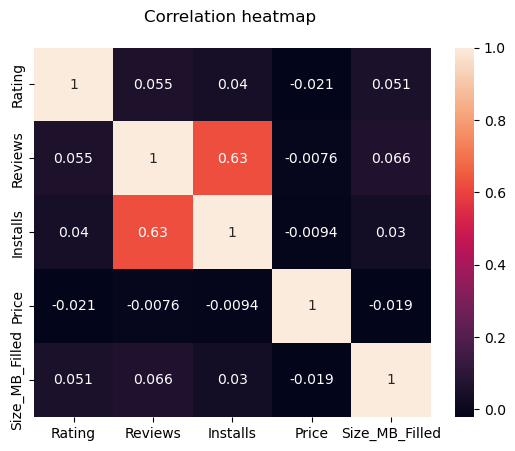

In [6]:
# Correlation heatmaps between Rating, Reviews, Installs, Price, Size_MB_Filled
heatmap_data = data[['Rating', 'Reviews', 'Installs', 'Price', 'Size_MB_Filled']].corr()
sns.heatmap(heatmap_data, annot=True)
plt.title("Correlation heatmap \n")
plt.show()

## Covariance analysis
### Determine whether the variables tend to increase or decrease

In [7]:
# Covariance analysis between Rating, Reviews, Installs, Price, Size_MB
pd.set_option('display.float_format', '{:.2f}'.format)
data[["Rating", "Reviews", "Installs", "Price", "Size_MB"]].cov()

,Rating,Reviews,Installs,Price,Size_MB
Rating,0.29,58716.67,1257381.69,-0.19,0.80
Reviews,58716.67,3354144104911.22,61552998924417.16,-234220.83,3666635.76
Installs,1257381.69,61552998924417.16,2891187855764967.50,-8526667.03,72786312.76
Price,-0.19,-234220.83,-8526667.03,283.98,-8.81
Size_MB,0.80,3666635.76,72786312.76,-8.81,476.51


## Installs vs Rating
### Investigating whether apps with more installs tend to have higher ratings

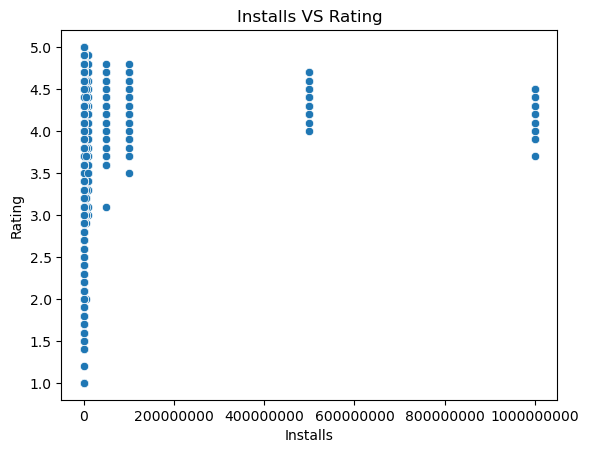

In [8]:
sns.scatterplot(data = data, x = data["Installs"], y = data["Rating"])
plt.ticklabel_format(style='plain', axis='x')
plt.title("Installs VS Rating")
plt.show()

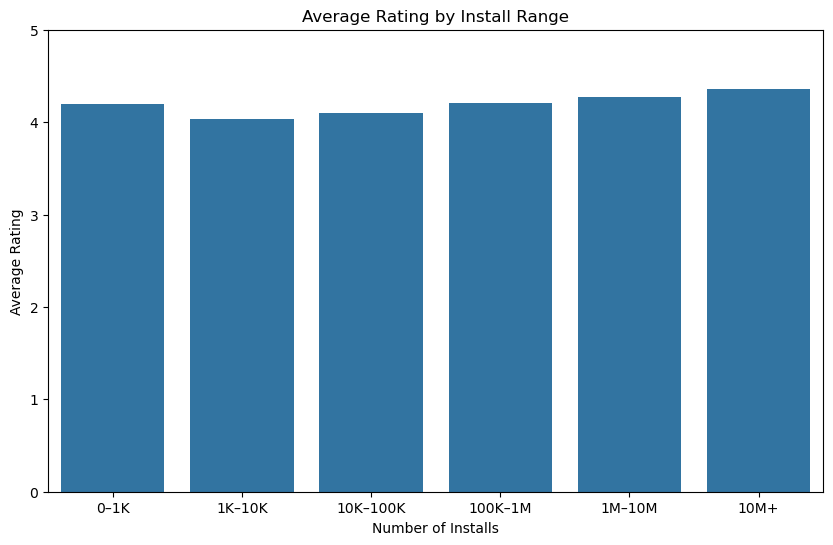

In [9]:
bins = [0, 1000, 10000, 100000, 1000000, 10000000, float('inf')]

labels = [
    '0–1K',
    '1K–10K',
    '10K–100K',
    '100K–1M',
    '1M–10M',
    '10M+'
]

data["Install_Range"] = pd.cut(
    data["Installs"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

grouped_data = data.groupby("Install_Range", observed=False)["Rating"].mean().reset_index()


plt.figure(figsize=(10, 6))

sns.barplot(
    data=grouped_data,
    x="Install_Range",
    y="Rating"
)

plt.title("Average Rating by Install Range")
plt.xlabel("Number of Installs")
plt.ylabel("Average Rating")
plt.ylim(0, 5)
plt.show()

## Installs vs Reviews
### Examine whether apps with more installs tend to receive more reviews

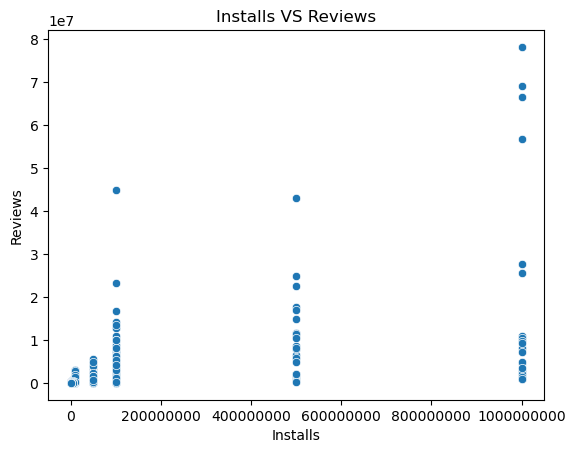

In [10]:
sns.scatterplot(data = data, x = data["Installs"], y = data["Reviews"])
plt.ticklabel_format(style='plain', axis='x')
plt.title("Installs VS Reviews")
plt.show()

## Free vs Paid app comparison
### Comparing the apps based on Rating

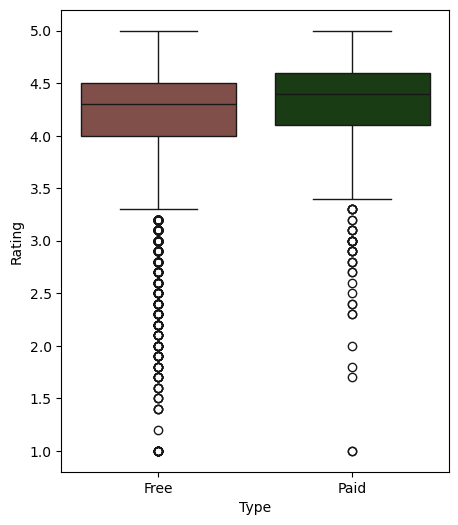

In [13]:
colors = ['#8A4841','#14420F','#192B48']
palette = sns.color_palette(colors)
plt.figure(figsize=(5,6))
sns.boxplot(data=data, x='Type', y='Rating', palette=palette)
plt.show()
import warnings
warnings.filterwarnings("ignore")

## Free vs Paid apps Installs
### Comparing the installs based on free and paid apps

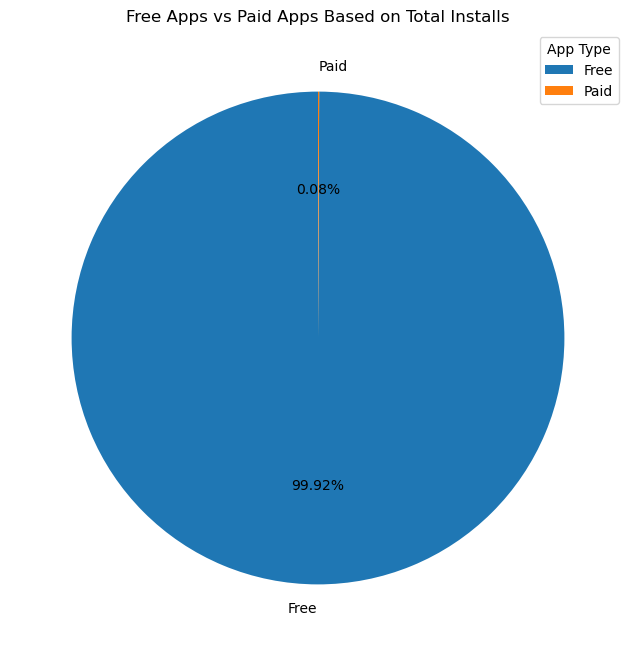

In [12]:
data["Installs"] = pd.to_numeric(data["Installs"], errors="coerce")
install_comparison = data.groupby("Type")["Installs"].sum()
plt.figure(figsize=(8, 8))
plt.pie(
    install_comparison,
    labels=install_comparison.index,
    autopct="%1.2f%%",
    startangle=90,
    # explode=(0.05, 0),
)

plt.title("Free Apps vs Paid Apps Based on Total Installs")
plt.legend(title="App Type")
plt.show()

# Trends
### 1. Free apps dominates the total installs